# ĐỒ ÁN: PHÂN TÍCH VÀ DỰ BÁO LƯỢNG HÀNH KHÁCH HÀNG KHÔNG

**Phương pháp:** SARIMA và ARIMA  
**Dữ liệu:** Air Passengers – lượng hành khách quốc tế theo tháng, 1949–1960  
**Nguồn dữ liệu:** [airline-passengers.csv trên GitHub](https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv)

## Mục tiêu

1. Vẽ chuỗi thời gian và nhận diện mùa vụ.
2. Kiểm định ADF trên chuỗi gốc.
3. Sai phân thường và sai phân mùa vụ.
4. Dùng ACF/PACF xác định các bậc `(p, q, P, Q)`.
5. Fit mô hình SARIMA.
6. Forecast và đánh giá bằng MAE/RMSE.
7. So sánh kết quả với ARIMA.

Tập test gồm 12 tháng cuối; mọi mô hình chỉ fit trên tập train. Các bậc SARIMA ứng viên được so sánh bằng AIC trên train, không dùng test để chọn mô hình.

## Chuẩn bị thư viện và dữ liệu

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, acf, pacf

DATA_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
SEASONAL_PERIOD = 12
TEST_MONTHS = 12
ALPHA = 0.05

data = pd.read_csv(DATA_URL, parse_dates=["Month"])
data = data.set_index("Month").sort_index()
data.index = pd.DatetimeIndex(data.index, freq="MS")
passengers = data["Passengers"].astype(float)

if passengers.index.has_duplicates:
    raise ValueError("Dữ liệu có tháng bị lặp.")
if passengers.isna().any():
    raise ValueError("Dữ liệu có giá trị thiếu; hãy kiểm tra lại nguồn dữ liệu.")
if not passengers.index.is_monotonic_increasing:
    raise ValueError("Thời gian phải được sắp xếp tăng dần.")

print(f"Số quan sát: {len(passengers)}")
print(f"Khoảng thời gian: {passengers.index.min():%Y-%m} đến {passengers.index.max():%Y-%m}")
print(f"Tần suất: {passengers.index.freqstr}")
print("\nNăm dòng đầu:")
print(data.head().to_string())

Số quan sát: 144
Khoảng thời gian: 1949-01 đến 1960-12
Tần suất: MS

Năm dòng đầu:
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121


## 1. Vẽ chuỗi thời gian → nhận diện mùa vụ

Thống kê mô tả, biểu đồ chuỗi thời gian, seasonal plot và heatmap giúp quan sát xu hướng tăng cũng như chu kỳ theo tháng.

Thống kê mô tả:
count    144.00
mean     280.30
std      119.97
min      104.00
25%      180.00
50%      265.50
75%      360.50
max      622.00

Số giá trị thiếu: 0
Tổng lượng hành khách trong dữ liệu (nghìn): 40,363


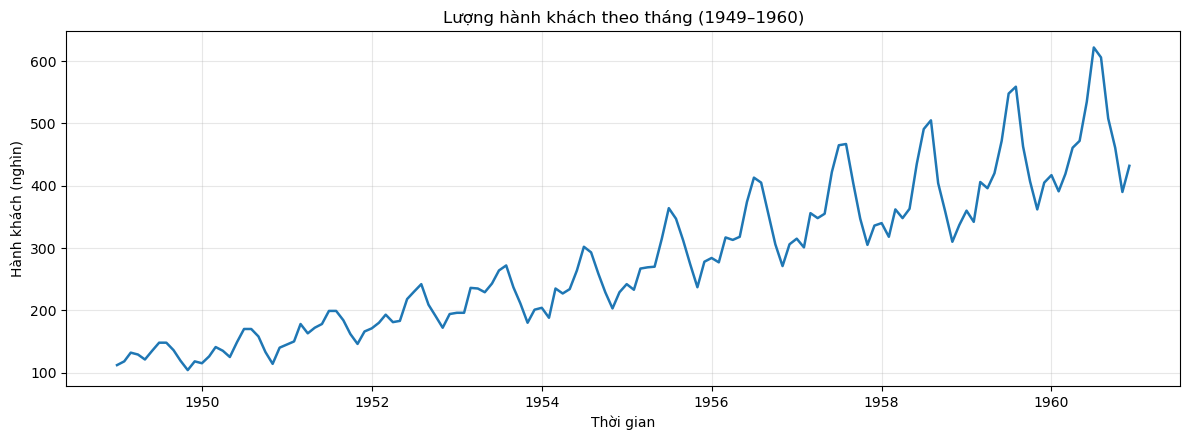

In [2]:
print("Thống kê mô tả:")
print(data["Passengers"].describe().round(2).to_string())
print(f"\nSố giá trị thiếu: {int(data['Passengers'].isna().sum())}")
print(f"Tổng lượng hành khách trong dữ liệu (nghìn): {passengers.sum():,.0f}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(passengers.index, passengers, linewidth=1.8)
ax.set(title="Lượng hành khách theo tháng (1949–1960)", xlabel="Thời gian", ylabel="Hành khách (nghìn)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

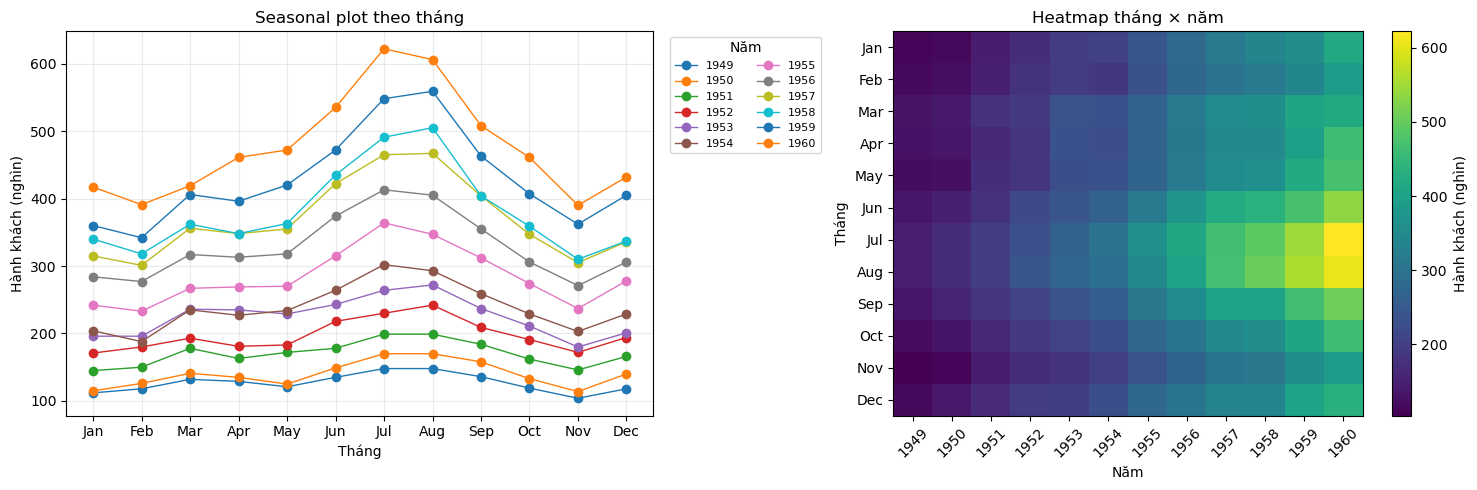


Trung bình tháng cao nhất: Jul (351.3)
Trung bình tháng thấp nhất: Nov (232.8)
Trung bình năm đầu/cuối: 126.7 (1949) / 476.2 (1960)
Thay đổi từ đầu đến cuối chuỗi: 285.7%


In [3]:
seasonal_data = data.assign(
    Year=data.index.year,
    Month_num=data.index.month,
)
seasonal_table = seasonal_data.pivot(index="Month_num", columns="Year", values="Passengers")
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for year in seasonal_table.columns:
    axes[0].plot(range(1, 13), seasonal_table[year], marker="o", linewidth=1, label=str(year))
axes[0].set_xticks(range(1, 13), month_labels)
axes[0].set(title="Seasonal plot theo tháng", xlabel="Tháng", ylabel="Hành khách (nghìn)")
axes[0].grid(alpha=0.25)
axes[0].legend(title="Năm", bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=8)

image = axes[1].imshow(seasonal_table.values, aspect="auto", origin="upper")
axes[1].set(title="Heatmap tháng × năm", xlabel="Năm", ylabel="Tháng")
axes[1].set_xticks(range(len(seasonal_table.columns)), seasonal_table.columns, rotation=45)
axes[1].set_yticks(range(12), month_labels)
fig.colorbar(image, ax=axes[1], label="Hành khách (nghìn)")
plt.tight_layout()
plt.show()

monthly_mean = seasonal_data.groupby("Month_num")["Passengers"].mean()
annual_mean = seasonal_data.groupby("Year")["Passengers"].mean()
print(f"\nTrung bình tháng cao nhất: {month_labels[monthly_mean.idxmax() - 1]} ({monthly_mean.max():.1f})")
print(f"Trung bình tháng thấp nhất: {month_labels[monthly_mean.idxmin() - 1]} ({monthly_mean.min():.1f})")
print(f"Trung bình năm đầu/cuối: {annual_mean.iloc[0]:.1f} ({annual_mean.index[0]}) / {annual_mean.iloc[-1]:.1f} ({annual_mean.index[-1]})")
print(f"Thay đổi từ đầu đến cuối chuỗi: {(passengers.iloc[-1] / passengers.iloc[0] - 1) * 100:.1f}%")

Biên độ chuỗi tăng dần cùng mức trung bình, các đỉnh thường rơi vào mùa hè và các mẫu lặp lại hằng năm. Điều này gợi ý chuỗi có xu hướng và mùa vụ 12 tháng; bước tiếp theo kiểm tra tính dừng trước khi fit mô hình.

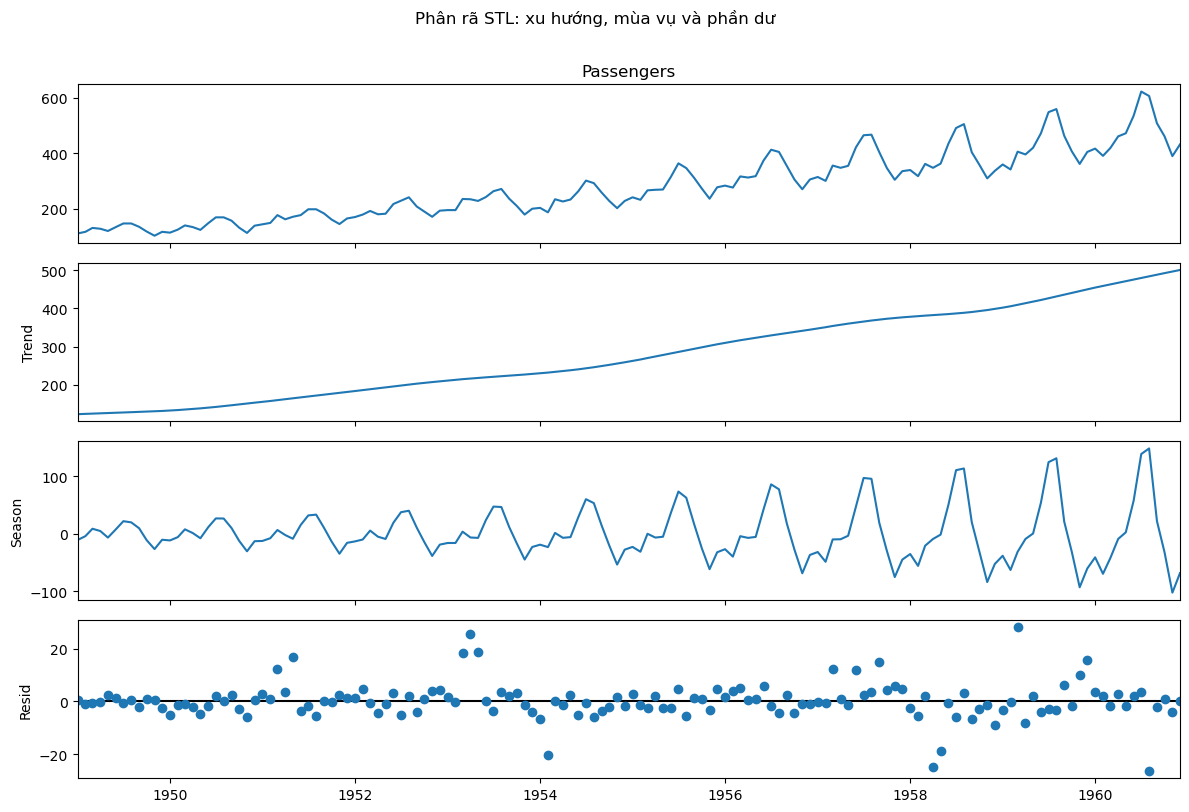

In [4]:
stl_result = STL(passengers, period=SEASONAL_PERIOD, robust=True).fit()
fig = stl_result.plot()
fig.set_size_inches(12, 8)
fig.suptitle("Phân rã STL: xu hướng, mùa vụ và phần dư", y=1.01)
plt.tight_layout()
plt.show()

## 2. ADF chuỗi gốc → kiểm tra tính không dừng

ADF có giả thuyết không (H₀) là chuỗi có nghiệm đơn vị, tức chưa dừng theo đặc tả kiểm định. Ở mức ý nghĩa 5%, p-value nhỏ hơn 0,05 là bằng chứng để bác bỏ H₀.

In [5]:
def run_adf(series):
    result = adfuller(series.dropna(), autolag="AIC")
    return {"ADF statistic": result[0], "p-value": result[1], "lags": result[2], "observations": result[3]}


adf_original = run_adf(passengers)
print(f"ADF statistic chuỗi gốc: {adf_original['ADF statistic']:.6f}")
print(f"p-value chuỗi gốc: {adf_original['p-value']:.6f}")
print(f"Số độ trễ: {adf_original['lags']}; số quan sát dùng trong kiểm định: {adf_original['observations']}")
print("Kết luận:", "bác bỏ H₀ ở mức 5%." if adf_original["p-value"] < ALPHA else "chưa đủ bằng chứng bác bỏ H₀; chuỗi có dấu hiệu không dừng.")

ADF statistic chuỗi gốc: 0.815369
p-value chuỗi gốc: 0.991880
Số độ trễ: 13; số quan sát dùng trong kiểm định: 130
Kết luận: chưa đủ bằng chứng bác bỏ H₀; chuỗi có dấu hiệu không dừng.


## 3. Sai phân thường + mùa vụ

Theo gợi ý đề bài, đặt sai phân thường `d=1`, sai phân mùa vụ `D=1` và chu kỳ mùa vụ `s=12`. ADF trên các chuỗi sai phân được dùng để kiểm tra lại tính dừng.

                                   ADF statistic   p-value  lags  observations  Dừng ở mức 5%
Chuỗi                                                                                        
Chuỗi gốc                               0.815369  0.991880    13           130          False
Sai phân thường (d=1)                  -2.829267  0.054213    12           130          False
Sai phân mùa vụ (D=1, s=12)            -3.383021  0.011551     1           130           True
Sai phân kết hợp (d=1, D=1, s=12)     -15.595618  0.000000     0           130           True


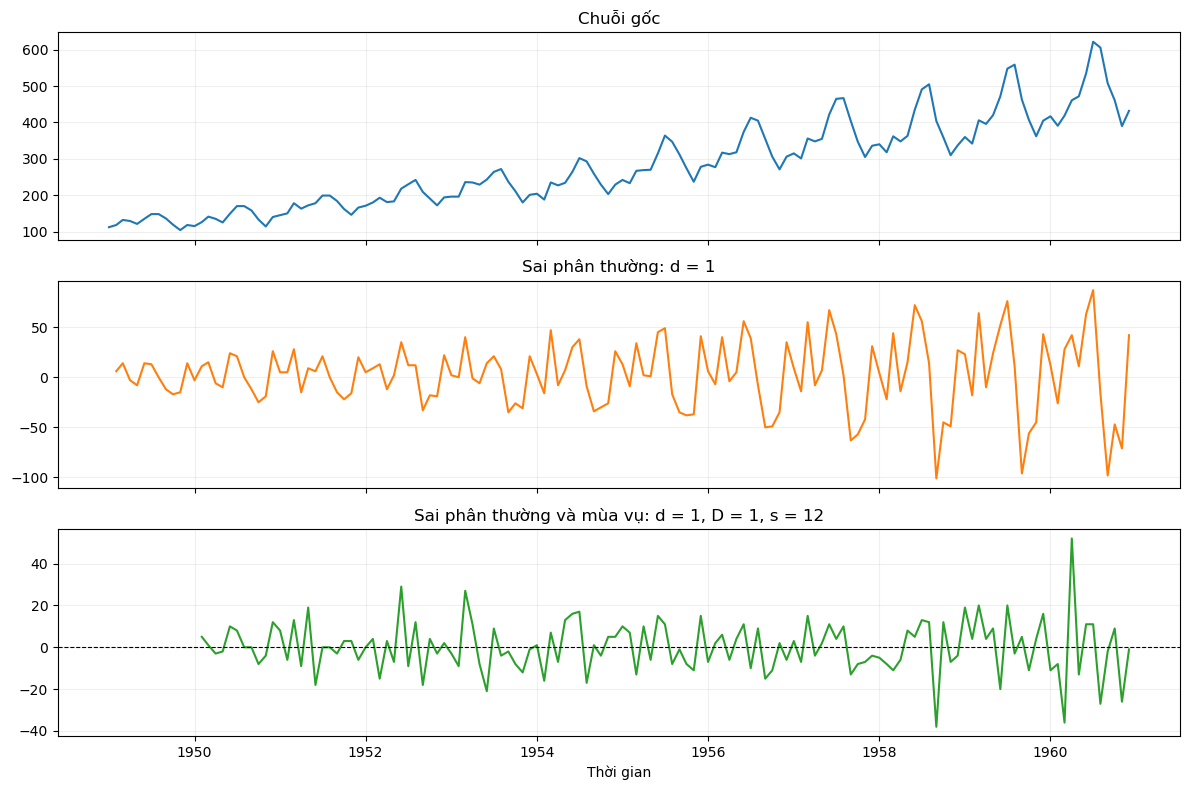


Diễn giải: p-value ADF nhỏ hơn 0,05 là bằng chứng chuỗi dừng theo kiểm định; đây không phải bảo đảm cho mọi cấu hình kiểm định.


In [6]:
difference_series = {
    "Chuỗi gốc": passengers,
    "Sai phân thường (d=1)": passengers.diff(1),
    "Sai phân mùa vụ (D=1, s=12)": passengers.diff(SEASONAL_PERIOD),
    "Sai phân kết hợp (d=1, D=1, s=12)": passengers.diff(1).diff(SEASONAL_PERIOD),
}

adf_rows = []
for label, series in difference_series.items():
    result = run_adf(series)
    adf_rows.append({"Chuỗi": label, **result, "Dừng ở mức 5%": result["p-value"] < ALPHA})
adf_table = pd.DataFrame(adf_rows).set_index("Chuỗi")
print(adf_table.round(6).to_string())

fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
axes[0].plot(passengers)
axes[0].set_title("Chuỗi gốc")
axes[1].plot(difference_series["Sai phân thường (d=1)"], color="tab:orange")
axes[1].set_title("Sai phân thường: d = 1")
axes[2].plot(difference_series["Sai phân kết hợp (d=1, D=1, s=12)"], color="tab:green")
axes[2].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[2].set_title("Sai phân thường và mùa vụ: d = 1, D = 1, s = 12")
axes[2].set_xlabel("Thời gian")
for ax in axes:
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print("\nDiễn giải: p-value ADF nhỏ hơn 0,05 là bằng chứng chuỗi dừng theo kiểm định; đây không phải bảo đảm cho mọi cấu hình kiểm định.")

Sai phân kết hợp giúp loại bỏ xu hướng và mùa vụ theo cấu hình đề xuất. ADF là một chẩn đoán; ta vẫn kiểm tra phần dư sau fit để đánh giá xem mô hình đã giải thích được tương quan còn lại hay chưa.

## 4. ACF/PACF → xác định (p, q, P, Q)

Giữ lại 12 tháng cuối làm test. ACF/PACF được xem trên phần train đã sai phân, tránh để các quan sát của tập test ảnh hưởng đến gợi ý bậc mô hình.

Train: 1949-01 đến 1959-12 (132 tháng)
Test:  1960-01 đến 1960-12 (12 tháng)


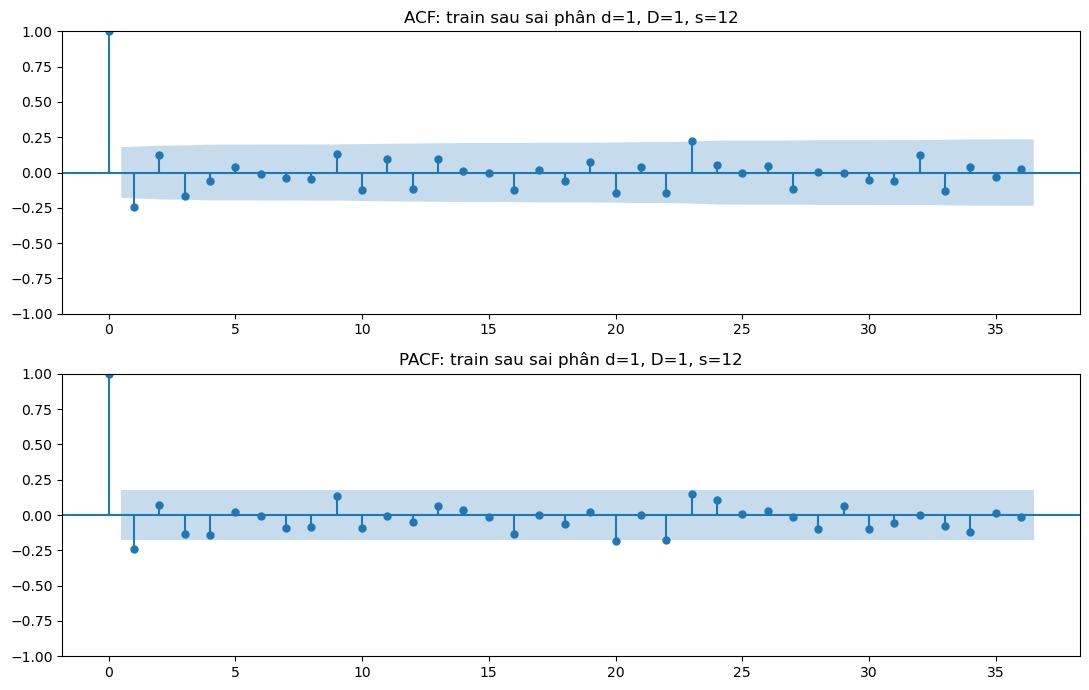


ACF/PACF tại một số lag:
       ACF   PACF
Lag              
1   -0.243 -0.243
2    0.123  0.068
12  -0.118 -0.047
13   0.097  0.061
24   0.050  0.106
36   0.024 -0.014
Ngưỡng tham khảo gần đúng 95%: ±0.180


In [7]:
train = passengers.iloc[:-TEST_MONTHS]
test = passengers.iloc[-TEST_MONTHS:]
train_diff = train.diff(1).diff(SEASONAL_PERIOD).dropna()

print(f"Train: {train.index[0]:%Y-%m} đến {train.index[-1]:%Y-%m} ({len(train)} tháng)")
print(f"Test:  {test.index[0]:%Y-%m} đến {test.index[-1]:%Y-%m} ({len(test)} tháng)")

fig, axes = plt.subplots(2, 1, figsize=(11, 7))
plot_acf(train_diff, lags=36, ax=axes[0])
axes[0].set_title("ACF: train sau sai phân d=1, D=1, s=12")
plot_pacf(train_diff, lags=36, method="ywm", ax=axes[1])
axes[1].set_title("PACF: train sau sai phân d=1, D=1, s=12")
plt.tight_layout()
plt.show()

acf_values = acf(train_diff, nlags=36)
pacf_values = pacf(train_diff, nlags=36, method="ywm")
key_lags = [1, 2, 12, 13, 24, 36]
correlation_table = pd.DataFrame(
    {"ACF": [acf_values[lag] for lag in key_lags], "PACF": [pacf_values[lag] for lag in key_lags]},
    index=key_lags,
)
correlation_table.index.name = "Lag"
print("\nACF/PACF tại một số lag:")
print(correlation_table.round(3).to_string())
print(f"Ngưỡng tham khảo gần đúng 95%: ±{1.96 / np.sqrt(len(train_diff)):.3f}")

ACF/PACF là công cụ tham khảo, không xác định duy nhất bậc mô hình. ACF/PACF sau sai phân giúp đề xuất các bậc thường và mùa vụ; ở bước 5 sẽ thử `p=0`, `q=1`, `P=0` với `Q=0` hoặc `Q=1`, giữ `d=1`, `D=1`, `s=12`. Chọn SARIMA theo AIC trên train; ARIMA không mùa vụ sẽ được fit ở bước 7 để so sánh.

## 5. Fit SARIMA

In [8]:
sarima_candidates = [
    ((0, 1, 1), (0, 1, 0, SEASONAL_PERIOD)),
    ((0, 1, 1), (0, 1, 1, SEASONAL_PERIOD)),
]

sarima_fits = {}
for order, seasonal_order in sarima_candidates:
    label = f"SARIMA{order}x{seasonal_order}"
    with warnings.catch_warnings():
        warnings.filterwarnings("ignore", category=UserWarning)
        fit = SARIMAX(
            train,
            order=order,
            seasonal_order=seasonal_order,
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False,
        ).fit(disp=False)
    sarima_fits[label] = {"order": order, "seasonal_order": seasonal_order, "fit": fit}

aic_table = pd.DataFrame(
    {label: {"AIC": item["fit"].aic, "BIC": item["fit"].bic} for label, item in sarima_fits.items()}
).T.sort_values("AIC")
print("SARIMA ứng viên (fit trên train):")
print(aic_table.round(2).to_string())

best_sarima_label = aic_table.index[0]
best_sarima = sarima_fits[best_sarima_label]
sarima_fit = best_sarima["fit"]
print(f"\nChọn {best_sarima_label} theo AIC thấp nhất trên train.")

SARIMA ứng viên (fit trên train):
                                  AIC     BIC
SARIMA(0, 1, 1)x(0, 1, 1, 12)  803.41  811.37
SARIMA(0, 1, 1)x(0, 1, 0, 12)  887.29  892.82

Chọn SARIMA(0, 1, 1)x(0, 1, 1, 12) theo AIC thấp nhất trên train.


### Chẩn đoán phần dư SARIMA (bổ sung)

Phần dư lý tưởng không còn tự tương quan đáng kể. Ljung–Box kiểm tra giả thuyết không rằng các tự tương quan đến lag 12 đồng thời bằng 0; p-value lớn hơn 0,05 nghĩa là chưa đủ bằng chứng bác bỏ giả thuyết này.

Kiểm định Ljung–Box trên phần dư SARIMA (lag 12):
    lb_stat  lb_pvalue
12  16.1454     0.0955


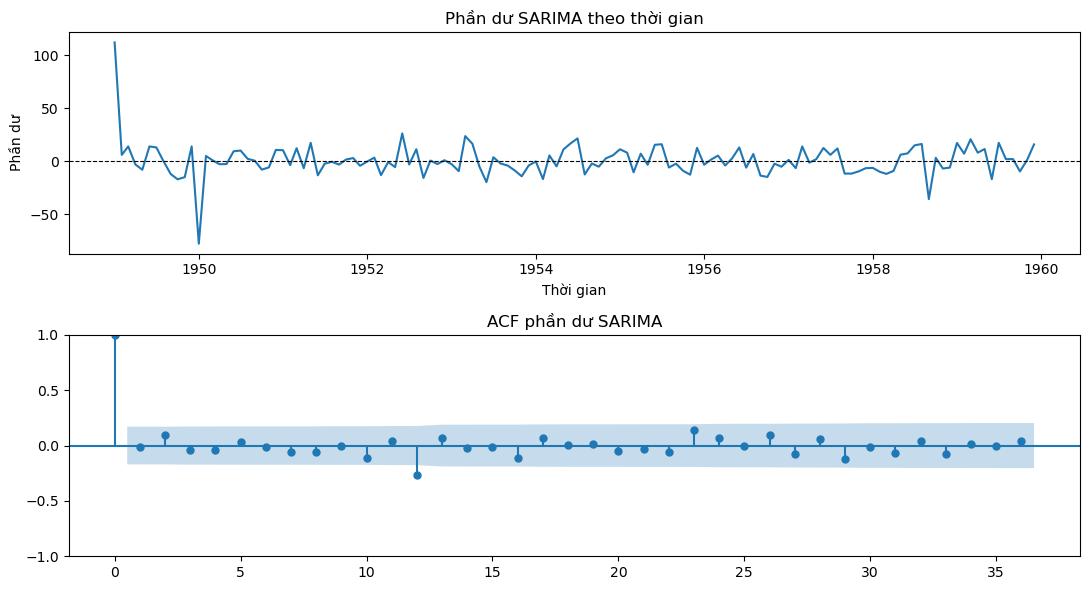

In [9]:
sarima_residuals = pd.Series(sarima_fit.resid).dropna()
ljung_box = acorr_ljungbox(sarima_residuals, lags=[12], model_df=2, return_df=True)
print("Kiểm định Ljung–Box trên phần dư SARIMA (lag 12):")
print(ljung_box.round(4).to_string())

fig, axes = plt.subplots(2, 1, figsize=(11, 6))
axes[0].plot(sarima_residuals)
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set(title="Phần dư SARIMA theo thời gian", xlabel="Thời gian", ylabel="Phần dư")
plot_acf(sarima_residuals, lags=36, ax=axes[1])
axes[1].set_title("ACF phần dư SARIMA")
plt.tight_layout()
plt.show()

## 6. Forecast và đánh giá SARIMA (MAE, RMSE)

Dự báo 12 tháng test bằng mô hình SARIMA đã chọn. MAE đo sai số tuyệt đối trung bình; RMSE nhạy hơn với sai số lớn. Đơn vị của các chỉ số là nghìn hành khách.

In [10]:
sarima_forecast = sarima_fit.get_forecast(steps=len(test)).predicted_mean
sarima_forecast.index = test.index

def calculate_metrics(actual, predicted):
    errors = np.asarray(actual) - np.asarray(predicted)
    return float(np.mean(np.abs(errors))), float(np.sqrt(np.mean(errors**2)))


sarima_mae, sarima_rmse = calculate_metrics(test, sarima_forecast)
sarima_metrics = pd.DataFrame(
    {"MAE": [sarima_mae], "RMSE": [sarima_rmse]},
    index=[best_sarima_label],
)
print("Đánh giá SARIMA trên tập test (đơn vị: nghìn hành khách):")
print(sarima_metrics.round(2).to_string())

sarima_forecast_table = pd.DataFrame({"Thực tế": test, "Dự báo SARIMA": sarima_forecast})
print("\nDự báo SARIMA chi tiết:")
print(sarima_forecast_table.round(1).to_string())

Đánh giá SARIMA trên tập test (đơn vị: nghìn hành khách):
                                 MAE   RMSE
SARIMA(0, 1, 1)x(0, 1, 1, 12)  16.09  20.93

Dự báo SARIMA chi tiết:
            Thực tế  Dự báo SARIMA
Month                             
1960-01-01    417.0          422.8
1960-02-01    391.0          404.5
1960-03-01    419.0          466.8
1960-04-01    461.0          456.5
1960-05-01    472.0          479.7
1960-06-01    535.0          533.4
1960-07-01    622.0          607.5
1960-08-01    606.0          618.7
1960-09-01    508.0          522.6
1960-10-01    461.0          467.5
1960-11-01    390.0          422.2
1960-12-01    432.0          463.8


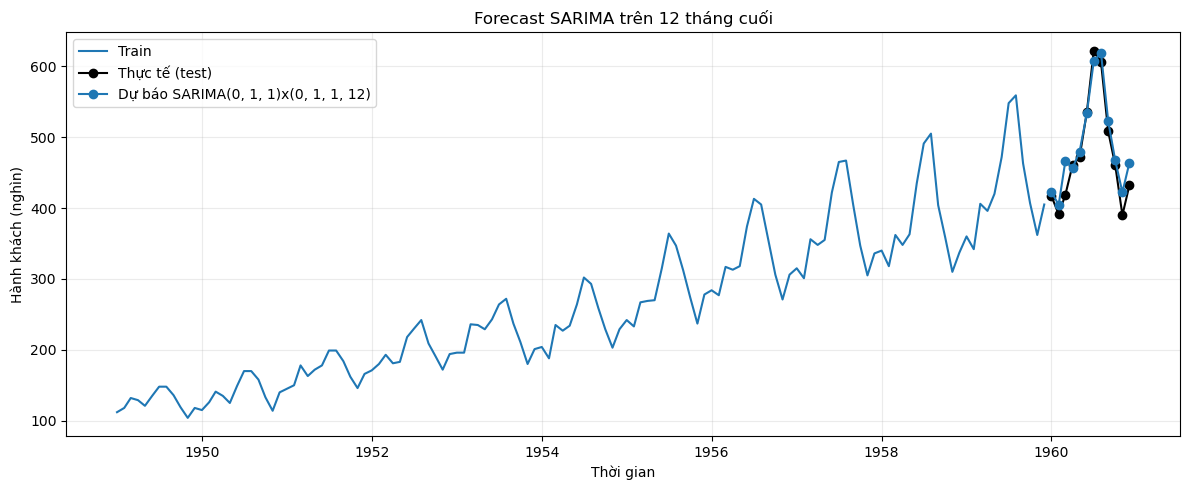

In [11]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index, train, label="Train", color="tab:blue")
ax.plot(test.index, test, label="Thực tế (test)", color="black", marker="o")
ax.plot(test.index, sarima_forecast, label=f"Dự báo {best_sarima_label}", marker="o")
ax.set(title="Forecast SARIMA trên 12 tháng cuối", xlabel="Thời gian", ylabel="Hành khách (nghìn)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. So sánh với ARIMA

ARIMA(1,1,1) được fit trên cùng tập train và dự báo cùng giai đoạn test. So sánh trực tiếp MAE/RMSE và biểu đồ để đánh giá lợi ích của thành phần mùa vụ SARIMA.

ARIMA(1, 1, 1): AIC = 1257.04; BIC = 1265.66

So sánh trên cùng tập test (đơn vị: nghìn hành khách):
                                 MAE   RMSE
SARIMA(0, 1, 1)x(0, 1, 1, 12)  16.09  20.93
ARIMA(1, 1, 1)                 66.24  91.23

Dự báo chi tiết:
            Thực tế  Dự báo SARIMA  Dự báo ARIMA
Month                                           
1960-01-01    417.0          422.8         433.5
1960-02-01    391.0          404.5         418.0
1960-03-01    419.0          466.8         426.4
1960-04-01    461.0          456.5         421.8
1960-05-01    472.0          479.7         424.3
1960-06-01    535.0          533.4         423.0
1960-07-01    622.0          607.5         423.7
1960-08-01    606.0          618.7         423.3
1960-09-01    508.0          522.6         423.5
1960-10-01    461.0          467.5         423.4
1960-11-01    390.0          422.2         423.5
1960-12-01    432.0          463.8         423.4

Mô hình có RMSE thấp nhất trên tập test: SARIMA(0, 1, 1)x(0, 1

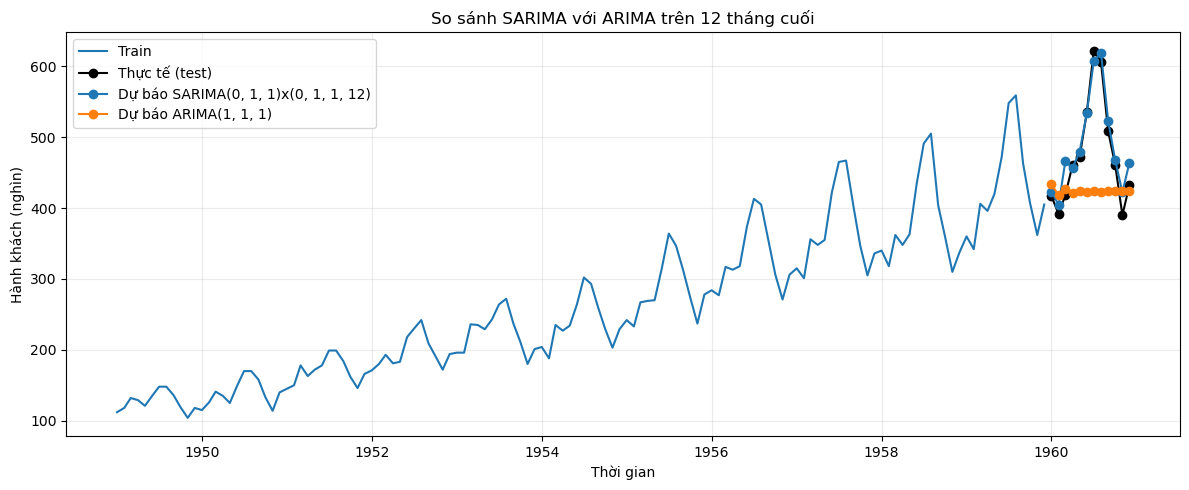

In [12]:
ARIMA_ORDER = (1, 1, 1)
arima_fit = ARIMA(train, order=ARIMA_ORDER, trend="n").fit()
arima_forecast = arima_fit.get_forecast(steps=len(test)).predicted_mean
arima_forecast.index = test.index

arima_mae, arima_rmse = calculate_metrics(test, arima_forecast)
results = pd.DataFrame(
    {
        "MAE": [sarima_mae, arima_mae],
        "RMSE": [sarima_rmse, arima_rmse],
    },
    index=[best_sarima_label, f"ARIMA{ARIMA_ORDER}"],
).sort_values("RMSE")
print(f"ARIMA{ARIMA_ORDER}: AIC = {arima_fit.aic:.2f}; BIC = {arima_fit.bic:.2f}")
print("\nSo sánh trên cùng tập test (đơn vị: nghìn hành khách):")
print(results.round(2).to_string())

forecast_table = pd.DataFrame(
    {"Thực tế": test, "Dự báo SARIMA": sarima_forecast, "Dự báo ARIMA": arima_forecast}
)
print("\nDự báo chi tiết:")
print(forecast_table.round(1).to_string())

best_test_model = results.index[0]
print(f"\nMô hình có RMSE thấp nhất trên tập test: {best_test_model}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(train.index, train, label="Train", color="tab:blue")
ax.plot(test.index, test, label="Thực tế (test)", color="black", marker="o")
ax.plot(test.index, sarima_forecast, label=f"Dự báo {best_sarima_label}", marker="o")
ax.plot(test.index, arima_forecast, label=f"Dự báo ARIMA{ARIMA_ORDER}", marker="o")
ax.set(title="So sánh SARIMA với ARIMA trên 12 tháng cuối", xlabel="Thời gian", ylabel="Hành khách (nghìn)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Kết luận

Kết luận số liệu dưới đây được tạo từ kết quả chạy notebook, vì vậy sẽ cập nhật theo các bậc mô hình được fit và dữ liệu tải về.

In [13]:
best_row = results.iloc[0]
worst_row = results.iloc[-1]
relative_rmse_improvement = (worst_row["RMSE"] - best_row["RMSE"]) / worst_row["RMSE"] * 100
combined_adf_pvalue = adf_table.loc["Sai phân kết hợp (d=1, D=1, s=12)", "p-value"]
lb_pvalue = ljung_box["lb_pvalue"].iloc[0]

print("1. Chuỗi có xu hướng tăng và mẫu mùa vụ lặp theo chu kỳ 12 tháng.")
print(f"2. ADF sau sai phân d=1, D=1, s=12: p-value = {combined_adf_pvalue:.6g}; "
      f"{'bác bỏ H₀ ở mức 5%' if combined_adf_pvalue < ALPHA else 'chưa bác bỏ H₀ ở mức 5%'}.")
print(f"3. SARIMA được chọn theo AIC train: {best_sarima_label} (AIC = {sarima_fit.aic:.2f}).")
print(f"4. Mô hình có RMSE test thấp nhất: {results.index[0]} "
      f"(MAE = {best_row['MAE']:.2f}; RMSE = {best_row['RMSE']:.2f}).")
print(f"5. RMSE giảm {relative_rmse_improvement:.1f}% so với mô hình còn lại trên giai đoạn test.")
print(f"6. Ljung–Box phần dư SARIMA tại lag 12: p-value = {lb_pvalue:.4f}; "
      f"{'chưa thấy tự tương quan còn lại có ý nghĩa ở mức 5%' if lb_pvalue >= ALPHA else 'còn dấu hiệu tự tương quan; nên xem xét cải thiện mô hình'}.")

print("\nLưu ý: đánh giá chỉ dùng một giai đoạn test 12 tháng; nên cân nhắc kiểm định cuốn chiếu (rolling-origin) trước khi triển khai dự báo thực tế.")

1. Chuỗi có xu hướng tăng và mẫu mùa vụ lặp theo chu kỳ 12 tháng.
2. ADF sau sai phân d=1, D=1, s=12: p-value = 1.85651e-28; bác bỏ H₀ ở mức 5%.
3. SARIMA được chọn theo AIC train: SARIMA(0, 1, 1)x(0, 1, 1, 12) (AIC = 803.41).
4. Mô hình có RMSE test thấp nhất: SARIMA(0, 1, 1)x(0, 1, 1, 12) (MAE = 16.09; RMSE = 20.93).
5. RMSE giảm 77.1% so với mô hình còn lại trên giai đoạn test.
6. Ljung–Box phần dư SARIMA tại lag 12: p-value = 0.0955; chưa thấy tự tương quan còn lại có ý nghĩa ở mức 5%.

Lưu ý: đánh giá chỉ dùng một giai đoạn test 12 tháng; nên cân nhắc kiểm định cuốn chiếu (rolling-origin) trước khi triển khai dự báo thực tế.
